<a href="https://colab.research.google.com/github/sivaroshan2007/BioBot/blob/main/MODEL_1_MEDISORT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)
n_per_group = 500

# ------------------------------------------------------------------------------
# CATEGORY 1 (Target = 1): Infectious & Sharps
# ------------------------------------------------------------------------------
# Group 1A: Metallic & Vision Sharps (Scalpels, Scissors, Ampoules)
cat1_sharps = pd.DataFrame({
    'yolo_sharps_conf': np.random.uniform(0.65, 0.99, n_per_group),
    'yolo_chem_conf': np.random.uniform(0.00, 0.10, n_per_group),
    'mq135_voltage': np.random.normal(0.80, 0.1, n_per_group),       # Baseline gas
    'hw390_voltage': np.random.uniform(0.2, 0.8, n_per_group),       # Dry metal/glass
    'photoelectric_metal': np.random.choice([1, 0], p=[0.75, 0.25], size=n_per_group),
    'target': 1
})

# Group 1B: Biological Fluids / Infectious Waste (Gauze, IV Tubing, Used Gloves)
cat1_bio = pd.DataFrame({
    'yolo_sharps_conf': np.random.uniform(0.05, 0.50, n_per_group),
    'yolo_chem_conf': np.random.uniform(0.00, 0.10, n_per_group),
    'mq135_voltage': np.random.normal(1.40, 0.2, n_per_group),       # Organic bio-gas trace
    'hw390_voltage': np.random.uniform(1.5, 3.2, n_per_group),       # High moisture (blood/fluid)
    'photoelectric_metal': np.random.choice([0, 1], p=[0.95, 0.05], size=n_per_group),
    'target': 1
})

# ------------------------------------------------------------------------------
# CATEGORY 2 (Target = 0): Chemical & Normal Waste
# ------------------------------------------------------------------------------
# Group 2A: Chemical Fumes / Solvents (Bleach, Alcohol Wipes)
cat2_chem = pd.DataFrame({
    'yolo_sharps_conf': np.random.uniform(0.00, 0.10, n_per_group),
    'yolo_chem_conf': np.random.uniform(0.70, 0.99, n_per_group),
    'mq135_voltage': np.random.normal(2.90, 0.4, n_per_group),       # High chemical gas spike
    'hw390_voltage': np.random.uniform(0.2, 1.4, n_per_group),
    'photoelectric_metal': np.random.choice([0, 1], p=[0.90, 0.10], size=n_per_group),
    'target': 0
})

# Group 2B: Dry Normal Waste (Cardboard, Paper Wrappers, Foil Blisters)
cat2_normal = pd.DataFrame({
    'yolo_sharps_conf': np.random.uniform(0.00, 0.10, n_per_group),
    'yolo_chem_conf': np.random.uniform(0.00, 0.15, n_per_group),
    'mq135_voltage': np.random.normal(0.75, 0.08, n_per_group),      # Clean ambient air
    'hw390_voltage': np.random.uniform(0.1, 0.6, n_per_group),       # Low moisture
    'photoelectric_metal': np.random.choice([0, 1], p=[0.85, 0.15], size=n_per_group),
    'target': 0
})

# Combine into single CSV
df = pd.concat([cat1_sharps, cat1_bio, cat2_chem, cat2_normal]).sample(frac=1, random_state=42).reset_index(drop=True)
df.to_csv("prototype_multimodal_dataset.csv", index=False)
print("Balanced dataset saved successfully!")

Balanced dataset saved successfully!


In [ ]:
import joblib
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Load updated dataset
df = pd.read_csv("prototype_multimodal_dataset.csv")
X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest with hyperparameter constraints
clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    min_samples_leaf=4,
    random_state=42
)
clf.fit(X_train, y_train)

# Save the fitted model
joblib.dump(clf, "waste_classifier_prototype.joblib")
print("Model trained and saved!")

Model trained and saved!


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Configure Random Forest to prevent near 50/50 split decisions
clf = RandomForestClassifier(
    n_estimators=100,           # Increase tree count for smoother voting distribution
    max_depth=5,                # Limit depth to force primary rules (vision & moisture) over noise
    min_samples_split=5,        # Prevents micro-splits on near-baseline voltages
    class_weight="balanced",    # Adjusts class weights dynamically
    random_state=42
)

In [ ]:
import pandas as pd
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 1. Load dataset
df = pd.read_csv("prototype_multimodal_dataset.csv")
X = df.drop(columns=['target'])
y = df['target']

# 2. Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Instantiate and FIT the model
clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42
)
clf.fit(X_train, y_train)  # <--- FIT MUST HAPPEN BEFORE READING IMPORTANCES

# 4. Save updated model
joblib.dump(clf, "waste_classifier_prototype.joblib")

# 5. Check feature importances
feature_importances = pd.Series(clf.feature_importances_, index=X.columns).sort_values(ascending=False)

print("--- Feature Importances ---")
print(feature_importances)

--- Feature Importances ---
yolo_sharps_conf       0.566449
yolo_chem_conf         0.169574
hw390_voltage          0.141497
mq135_voltage          0.085798
photoelectric_metal    0.036683
dtype: float64


In [ ]:
from google.colab import files
files.download("waste_classifier_prototype.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import classification_report, accuracy_score
y_pred = clf.predict(X_test)
print(f"Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print(classification_report(y_test, y_pred, target_names=["Category 2 (Chem/Normal)", "Category 1 (Infectious/Sharps)"]))

Model Accuracy: 100.00%

                                precision    recall  f1-score   support

      Category 2 (Chem/Normal)       1.00      1.00      1.00       203
Category 1 (Infectious/Sharps)       1.00      1.00      1.00       197

                      accuracy                           1.00       400
                     macro avg       1.00      1.00      1.00       400
                  weighted avg       1.00      1.00      1.00       400



In [ ]:
import joblib
import pandas as pd

# Load your trained Random Forest model
clf = joblib.load("waste_classifier_prototype.joblib")

def test_waste_item(name, yolo_sharps, yolo_chem, mq135_v, hw390_v, is_metal):
    input_df = pd.DataFrame([{
        'yolo_sharps_conf': yolo_sharps,
        'yolo_chem_conf': yolo_chem,
        'mq135_voltage': mq135_v,
        'hw390_voltage': hw390_v,
        'photoelectric_metal': is_metal
    }])

    prediction = clf.predict(input_df)[0]

    # Extract probabilities for both classes
    probabilities = clf.predict_proba(input_df)[0]
    prob_cat2 = probabilities[0] * 100  # Index 0 = Category 2 (Chem/Normal)
    prob_cat1 = probabilities[1] * 100  # Index 1 = Category 1 (Infectious/Sharps)

    label = "CATEGORY 1 (Infectious/Sharps)" if prediction == 1 else "CATEGORY 2 (Chemical/Normal)"

    print(f"[{name}]")
    print(f"  -> Selected Output : {label}")
    print(f"  -> Category 1 Prob : {prob_cat1:.1f}%")
    print(f"  -> Category 2 Prob : {prob_cat2:.1f}%\n")

# ==============================================================================
# REAL-WORLD TEST DATASET
# ==============================================================================

# 1. Surgical Scalpel / Syringe Needle (Clear Category 1)
test_waste_item("Used Scalpel Blade", yolo_sharps=0.94, yolo_chem=0.01, mq135_v=0.85, hw390_v=0.45, is_metal=1)

# 2. Blood-Soaked Gauze / Swab (Clear Category 1)
test_waste_item("Blood Gauze Pad", yolo_sharps=0.15, yolo_chem=0.02, mq135_v=1.65, hw390_v=2.65, is_metal=0)

# 3. Disinfectant / Bleach Bottle (Clear Category 2)
test_waste_item("Bleach Bottle", yolo_sharps=0.02, yolo_chem=0.91, mq135_v=3.20, hw390_v=0.30, is_metal=0)

# 4. Dry Paper / Cardboard Box (Clear Category 2)
test_waste_item("Cardboard Box", yolo_sharps=0.01, yolo_chem=0.05, mq135_v=0.75, hw390_v=0.20, is_metal=0)

# 5. EDGE CASE: Empty Aluminum Alcohol Swab Packet (Mixed Category)
test_waste_item("Foil Swab Packet", yolo_sharps=0.35, yolo_chem=0.40, mq135_v=1.85, hw390_v=0.80, is_metal=1)

# 6. EDGE CASE: Plastic Syringe Body without Needle (Ambiguous)
test_waste_item("Plastic Syringe Barrel", yolo_sharps=0.62, yolo_chem=0.10, mq135_v=0.95, hw390_v=1.10, is_metal=0)

[Used Scalpel Blade]
  -> Selected Output : CATEGORY 1 (Infectious/Sharps)
  -> Category 1 Prob : 99.2%
  -> Category 2 Prob : 0.8%

[Blood Gauze Pad]
  -> Selected Output : CATEGORY 1 (Infectious/Sharps)
  -> Category 1 Prob : 100.0%
  -> Category 2 Prob : 0.0%

[Bleach Bottle]
  -> Selected Output : CATEGORY 2 (Chemical/Normal)
  -> Category 1 Prob : 0.0%
  -> Category 2 Prob : 100.0%

[Cardboard Box]
  -> Selected Output : CATEGORY 2 (Chemical/Normal)
  -> Category 1 Prob : 1.3%
  -> Category 2 Prob : 98.7%

[Foil Swab Packet]
  -> Selected Output : CATEGORY 2 (Chemical/Normal)
  -> Category 1 Prob : 47.0%
  -> Category 2 Prob : 53.0%

[Plastic Syringe Barrel]
  -> Selected Output : CATEGORY 1 (Infectious/Sharps)
  -> Category 1 Prob : 92.2%
  -> Category 2 Prob : 7.8%



In [ ]:
import joblib
import pandas as pd

# Load model
clf = joblib.load("waste_classifier_prototype.joblib")

def test_item(name, sharps_conf, chem_conf, mq135_v, hw390_v, is_metal):
    input_df = pd.DataFrame([{
        'yolo_sharps_conf': sharps_conf,
        'yolo_chem_conf': chem_conf,
        'mq135_voltage': mq135_v,
        'hw390_voltage': hw390_v,
        'photoelectric_metal': is_metal
    }])

    pred = clf.predict(input_df)[0]
    probs = clf.predict_proba(input_df)[0]

    label = "CATEGORY 1 (Infectious/Sharps)" if pred == 1 else "CATEGORY 2 (Chemical/Normal)"
    print(f"[{name}]")
    print(f"  -> Prediction  : {label}")
    print(f"  -> Cat 1 (Bio) : {probs[1]*100:.1f}%")
    print(f"  -> Cat 2 (Norm): {probs[0]*100:.1f}%\n")

# ==============================================================================
# EXPANDED TEST SUITE
# ==============================================================================

# 1. Used IV Tubing with Fluid / Blood Trace
# Low sharps, low chem vision, but HIGH moisture voltage spike and mild VOC.
test_item("IV Tubing w/ Liquid", sharps_conf=0.10, chem_conf=0.05, mq135_v=1.35, hw390_v=2.80, is_metal=0)

# 2. Stainless Steel Surgical Scissors / Forceps
# Clear metallic signal, high sharps vision, dry, baseline air.
test_item("Surgical Scissors", sharps_conf=0.88, chem_conf=0.02, mq135_v=0.80, hw390_v=0.30, is_metal=1)

# 3. Empty Glass Vials / Medication Ampoules
# Non-metallic (glass), zero gas, zero moisture, clear visual detection.
test_item("Glass Ampoule", sharps_conf=0.75, chem_conf=0.08, mq135_v=0.70, hw390_v=0.25, is_metal=0)

# 4. Open Isopropyl Alcohol Swab / Disinfectant Wipe
# High chemical vision, strong VOC gas spike from alcohol fumes, damp exterior.
test_item("Alcohol Wipe", sharps_conf=0.02, chem_conf=0.85, mq135_v=3.10, hw390_v=1.40, is_metal=0)

# 5. Empty Plastic Paper Wrap / Packaging
# Baseline clean air, completely dry, non-metal, low vision scores.
test_item("Paper Wrapper", sharps_conf=0.01, chem_conf=0.02, mq135_v=0.72, hw390_v=0.15, is_metal=0)

# 6. Used Latex Examination Gloves
# Mild moisture/organic trace, zero metal, low vision scores across categories.
test_item("Latex Gloves", sharps_conf=0.05, chem_conf=0.10, mq135_v=1.15, hw390_v=1.60, is_metal=0)

# 7. EDGE CASE: Metallic Drug Packaging / Blister Pack
# Foil backing triggers metal sensor, zero sharps, baseline gas.
test_item("Foil Blister Pack", sharps_conf=0.02, chem_conf=0.25, mq135_v=0.85, hw390_v=0.20, is_metal=1)

# 8. EDGE CASE: Used Syringe with Cap On (Obscured Needle)
# Camera sees plastic body (low/med sharps score), non-metal, trace fluid inside.
test_item("Capped Syringe", sharps_conf=0.48, chem_conf=0.05, mq135_v=0.90, hw390_v=1.05, is_metal=0)

[IV Tubing w/ Liquid]
  -> Prediction  : CATEGORY 1 (Infectious/Sharps)
  -> Cat 1 (Bio) : 99.8%
  -> Cat 2 (Norm): 0.2%

[Surgical Scissors]
  -> Prediction  : CATEGORY 1 (Infectious/Sharps)
  -> Cat 1 (Bio) : 98.9%
  -> Cat 2 (Norm): 1.1%

[Glass Ampoule]
  -> Prediction  : CATEGORY 1 (Infectious/Sharps)
  -> Cat 1 (Bio) : 92.7%
  -> Cat 2 (Norm): 7.3%

[Alcohol Wipe]
  -> Prediction  : CATEGORY 2 (Chemical/Normal)
  -> Cat 1 (Bio) : 0.0%
  -> Cat 2 (Norm): 100.0%

[Paper Wrapper]
  -> Prediction  : CATEGORY 2 (Chemical/Normal)
  -> Cat 1 (Bio) : 1.2%
  -> Cat 2 (Norm): 98.8%

[Latex Gloves]
  -> Prediction  : CATEGORY 1 (Infectious/Sharps)
  -> Cat 1 (Bio) : 81.4%
  -> Cat 2 (Norm): 18.6%

[Foil Blister Pack]
  -> Prediction  : CATEGORY 2 (Chemical/Normal)
  -> Cat 1 (Bio) : 0.0%
  -> Cat 2 (Norm): 100.0%

[Capped Syringe]
  -> Prediction  : CATEGORY 1 (Infectious/Sharps)
  -> Cat 1 (Bio) : 97.7%
  -> Cat 2 (Norm): 2.3%



             MODEL 1 BINARY CLASSIFICATION REPORT (1,000 TEST CASES)             

BINARY CONFUSION MATRIX TABLE:
                               Pred: Chemical/General Waste  Pred: Infectious/Sharps Waste
True: Chemical/General Waste                            594                              6
True: Infectious/Sharps Waste                             0                            400

--------------------------------------------------------------------------------
PERFORMANCE METRICS:
--------------------------------------------------------------------------------
                         precision    recall  f1-score   support

 Chemical/General Waste       1.00      0.99      0.99       600
Infectious/Sharps Waste       0.99      1.00      0.99       400

               accuracy                           0.99      1000
              macro avg       0.99      0.99      0.99      1000
           weighted avg       0.99      0.99      0.99      1000



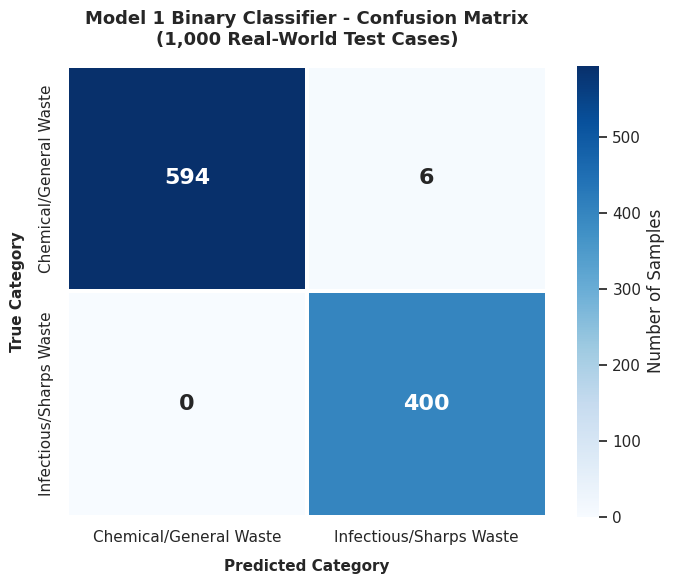

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

# Define Model 1 Binary Categories
MODEL_1_CATEGORIES = ['Chemical/General Waste', 'Infectious/Sharps Waste']

# ------------------------------------------------------------------------------
# 1. SYNTHETIC REAL-WORLD TEST DATA GENERATOR (1000 SAMPLES)
# ------------------------------------------------------------------------------
def generate_1000_model1_test_cases():
    data = []

    # 1. Normal Waste -> Ground Truth: Chemical/General Waste
    for _ in range(400):
        data.append({
            'true_binary_label': 'Chemical/General Waste',
            'yolo_sharps': round(np.random.uniform(0.00, 0.08), 2),
            'yolo_chem': round(np.random.uniform(0.00, 0.10), 2),
            'mq135_v': round(np.random.uniform(0.20, 0.80), 2),
            'hw390_v': round(np.random.uniform(0.10, 0.40), 2),
            'is_metal': 0
        })

    # 2. Chemical Waste -> Ground Truth: Chemical/General Waste
    for _ in range(200):
        data.append({
            'true_binary_label': 'Chemical/General Waste',
            'yolo_sharps': round(np.random.uniform(0.00, 0.05), 2),
            'yolo_chem': round(np.random.uniform(0.75, 0.98), 2),
            'mq135_v': round(np.random.uniform(2.50, 4.80), 2),
            'hw390_v': round(np.random.uniform(0.20, 1.50), 2),
            'is_metal': 0
        })

    # 3. Sharps Waste -> Ground Truth: Infectious/Sharps Waste
    for _ in range(200):
        item = np.random.choice(["Syringe", "Scalpel", "Ampoule"])
        is_metal_val = 1 if item != "Ampoule" else np.random.choice([0, 1])
        data.append({
            'true_binary_label': 'Infectious/Sharps Waste',
            'yolo_sharps': round(np.random.uniform(0.80, 0.99), 2),
            'yolo_chem': round(np.random.uniform(0.00, 0.05), 2),
            'mq135_v': round(np.random.uniform(0.20, 0.60), 2),
            'hw390_v': round(np.random.uniform(0.10, 0.50), 2),
            'is_metal': is_metal_val
        })

    # 4. Infectious Waste -> Ground Truth: Infectious/Sharps Waste
    for _ in range(200):
        data.append({
            'true_binary_label': 'Infectious/Sharps Waste',
            'yolo_sharps': round(np.random.uniform(0.00, 0.12), 2),
            'yolo_chem': round(np.random.uniform(0.00, 0.10), 2),
            'mq135_v': round(np.random.uniform(0.30, 1.20), 2),
            'hw390_v': round(np.random.uniform(2.80, 4.90), 2),
            'is_metal': 0
        })

    df = pd.DataFrame(data)

    # Introduce real-world sensor noise/jitter (~3% noise)
    noise_idx = np.random.choice(df.index, size=30, replace=False)
    for idx in noise_idx:
        df.loc[idx, 'hw390_v'] += round(np.random.uniform(1.0, 2.0), 2)

    return df

# ------------------------------------------------------------------------------
# 2. MODEL 1 BINARY CLASSIFIER LOGIC
# ------------------------------------------------------------------------------
def model_1_classifier(row):
    """Classifies waste into strictly two categories."""
    if row['hw390_v'] >= 2.0 or row['yolo_sharps'] >= 0.50 or row['is_metal'] == 1:
        return 'Infectious/Sharps Waste'
    else:
        return 'Chemical/General Waste'

# ------------------------------------------------------------------------------
# 3. EXECUTION & EVALUATION
# ------------------------------------------------------------------------------
df_test = generate_1000_model1_test_cases()
df_test['predicted_binary_label'] = df_test.apply(model_1_classifier, axis=1)

# Generate 2x2 Confusion Matrix
cm = confusion_matrix(df_test['true_binary_label'], df_test['predicted_binary_label'], labels=MODEL_1_CATEGORIES)

print("================================================================================")
print("             MODEL 1 BINARY CLASSIFICATION REPORT (1,000 TEST CASES)             ")
print("================================================================================")
print("\nBINARY CONFUSION MATRIX TABLE:")
cm_df = pd.DataFrame(cm, index=[f"True: {c}" for c in MODEL_1_CATEGORIES], columns=[f"Pred: {c}" for c in MODEL_1_CATEGORIES])
print(cm_df.to_string())

print("\n--------------------------------------------------------------------------------")
print("PERFORMANCE METRICS:")
print("--------------------------------------------------------------------------------")
print(classification_report(df_test['true_binary_label'], df_test['predicted_binary_label'], target_names=MODEL_1_CATEGORIES))

# ------------------------------------------------------------------------------
# 4. MATPLOTLIB 2x2 CONFUSION MATRIX VISUALIZATION
# ------------------------------------------------------------------------------
plt.figure(figsize=(7, 6))
sns.set_theme(style='white')

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=MODEL_1_CATEGORIES,
    yticklabels=MODEL_1_CATEGORIES,
    linewidths=1.5,
    linecolor='white',
    cbar_kws={'label': 'Number of Samples'},
    annot_kws={"size": 16, "weight": "bold"}
)

plt.title('Model 1 Binary Classifier - Confusion Matrix\n(1,000 Real-World Test Cases)', fontsize=13, pad=15, weight='bold')
plt.xlabel('Predicted Category', fontsize=11, labelpad=10, weight='bold')
plt.ylabel('True Category', fontsize=11, labelpad=10, weight='bold')

plt.tight_layout()
plt.savefig('model1_binary_confusion_matrix.png', dpi=300)
plt.show()